In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import cross_val_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load saved preprocessing artifacts
data = joblib.load("../artifacts/processed_data.pkl")

X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]

# Load preprocessing pipeline
preprocessor = joblib.load("../artifacts/preprocessor.pkl")

print("Dataset loaded successfully!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Dataset loaded successfully!
Training Features: (316, 56)
Testing Features: (79, 56)
Training Target: (316,)
Testing Target: (79,)


In [3]:
# Baseline Model
dummy_model = DummyRegressor(strategy="mean")

# Train the model
dummy_model.fit(X_train, y_train)

# Generate predictions
dummy_predictions = dummy_model.predict(X_test)

# Evaluate baseline performance
dummy_mae = mean_absolute_error(y_test, dummy_predictions)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_predictions))
dummy_r2 = r2_score(y_test, dummy_predictions)

print("Baseline Model Performance")
print("--------------------------")
print("MAE:", round(dummy_mae, 3))
print("RMSE:", round(dummy_rmse, 3))
print("R2 Score:", round(dummy_r2, 3))

Baseline Model Performance
--------------------------
MAE: 3.646
RMSE: 4.55
R2 Score: -0.01


In [4]:
# Initialize Linear Regression
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

# Generate predictions
lr_predictions = lr_model.predict(X_test)

# Evaluate model
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Performance")
print("------------------------------")
print("MAE:", round(lr_mae, 3))
print("RMSE:", round(lr_rmse, 3))
print("R2 Score:", round(lr_r2, 3))

Linear Regression Performance
------------------------------
MAE: 3.395
RMSE: 4.196
R2 Score: 0.141


In [5]:
# Initialize Decision Tree Regressor

dt_model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

# Train model
dt_model.fit(X_train, y_train)

# Generate predictions
dt_predictions = dt_model.predict(X_test)

# Evaluate model
dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_predictions))
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Performance")
print("--------------------------")
print("MAE:", round(dt_mae, 3))
print("RMSE:", round(dt_rmse, 3))
print("R2 Score:", round(dt_r2, 3))

Decision Tree Performance
--------------------------
MAE: 3.523
RMSE: 4.662
R2 Score: -0.06


In [6]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Performance")
print("--------------------------")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))

Random Forest Performance
--------------------------
MAE: 3.166
RMSE: 3.934
R2 Score: 0.245


### 5. Gradient Boosting Regressor

In [7]:

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting Performance")
print("-----------------------------")
print("MAE:", round(gb_mae, 3))
print("RMSE:", round(gb_rmse, 3))
print("R2 Score:", round(gb_r2, 3))


Gradient Boosting Performance
-----------------------------
MAE: 3.218
RMSE: 4.003
R2 Score: 0.218


### 6. Cross-Validation

In [8]:

models = {
    "Linear Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    cv_results.append({
        "Model": name,
        "Mean CV MAE": round(-scores.mean(), 3),
        "CV Std": round(scores.std(), 3)
    })

cv_df = pd.DataFrame(cv_results)

print("5-Fold Cross-Validation Results")
display(cv_df.sort_values("Mean CV MAE"))


5-Fold Cross-Validation Results


,Model,Mean CV MAE,CV Std
2,Random Forest,2.959,0.198
3,Gradient Boosting,3.064,0.190
1,Decision Tree,3.192,0.191
0,Linear Regression,3.576,0.161


### 7. Overfitting Analysis

In [9]:

train_predictions = rf_model.predict(X_train)
test_predictions = rf_model.predict(X_test)

train_mae = mean_absolute_error(y_train, train_predictions)
test_mae = mean_absolute_error(y_test, test_predictions)

train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)

print("Random Forest - Overfitting Analysis")
print("------------------------------------")
print("Training MAE:", round(train_mae, 3))
print("Testing MAE:", round(test_mae, 3))
print("Training R2:", round(train_r2, 3))
print("Testing R2:", round(test_r2, 3))
print("MAE Gap:", round(test_mae - train_mae, 3))


Random Forest - Overfitting Analysis
------------------------------------
Training MAE: 2.253
Testing MAE: 3.166
Training R2: 0.581
Testing R2: 0.245
MAE Gap: 0.913


In [11]:

rf_tuned = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features=0.8,
    random_state=42
)

rf_tuned.fit(X_train, y_train)

tuned_predictions = rf_tuned.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("MAE:", round(tuned_mae, 3))
print("RMSE:", round(tuned_rmse, 3))
print("R2 Score:", round(tuned_r2, 3))


Tuned Random Forest Performance
--------------------------------
MAE: 3.235
RMSE: 4.004
R2 Score: 0.218


### 8. Original vs Tuned Random Forest Generalization

In [12]:

comparison_models = {
    "Original Random Forest": rf_model,
    "Tuned Random Forest": rf_tuned
}

results = []

for name, model in comparison_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    results.append({
        "Model": name,
        "Train MAE": round(train_mae, 3),
        "Test MAE": round(test_mae, 3),
        "MAE Gap": round(test_mae - train_mae, 3),
        "CV MAE": round(-cv_scores.mean(), 3),
        "CV Std": round(cv_scores.std(), 3)
    })

comparison_df = pd.DataFrame(results)

display(comparison_df)


,Model,Train MAE,Test MAE,MAE Gap,CV MAE,CV Std
0,Original Random Forest,2.253,3.166,0.913,2.959,0.198
1,Tuned Random Forest,2.526,3.235,0.709,2.979,0.191


### 9. Actual vs Predicted Values

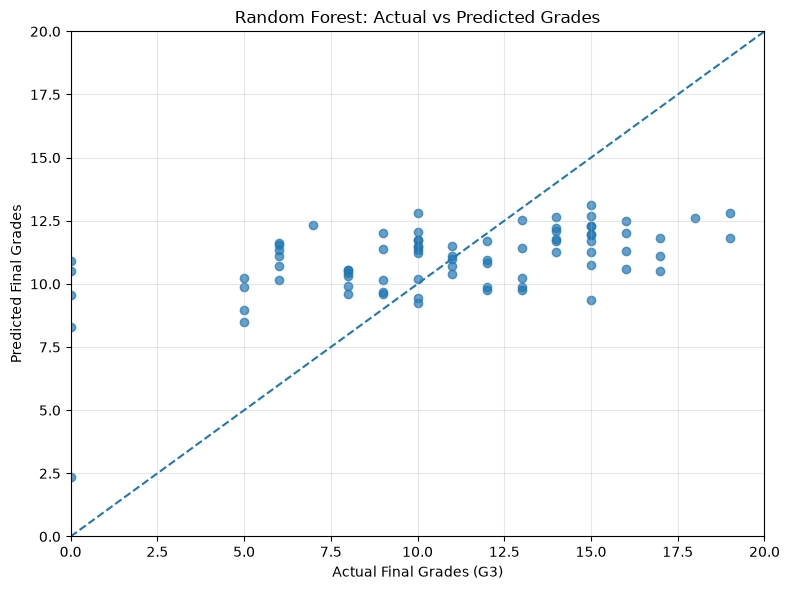

In [13]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.7
)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--"
)

plt.xlabel("Actual Final Grades (G3)")
plt.ylabel("Predicted Final Grades")
plt.title("Random Forest: Actual vs Predicted Grades")

plt.xlim(0, 20)
plt.ylim(0, 20)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 10. Residual Analysis

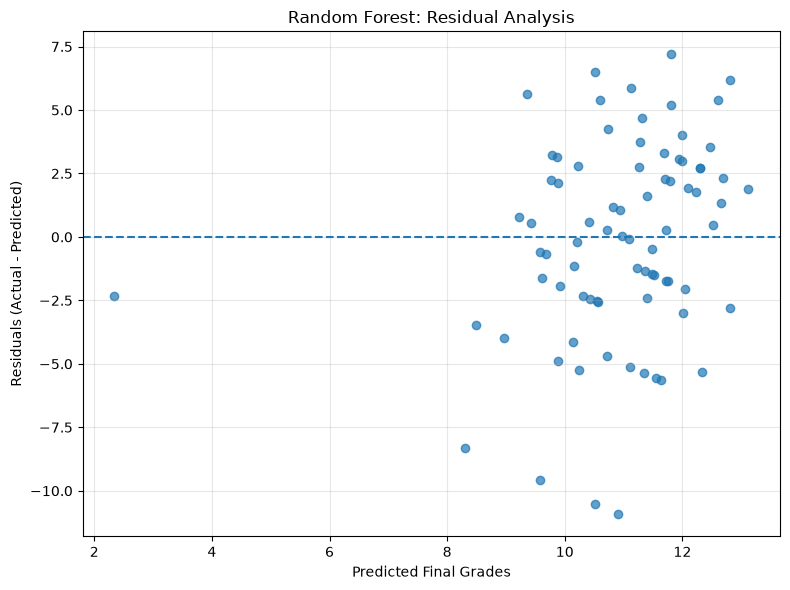

In [14]:

residuals = y_test - rf_predictions

plt.figure(figsize=(8, 6))

plt.scatter(
    rf_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Final Grades")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Random Forest: Residual Analysis")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 11. Feature Importance Analysis

In [15]:

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features")
display(importance_df.head(15))


Top 15 Important Features


,Feature,Importance
55,num__absences,0.269371
48,num__failures,0.241850
54,num__health,0.048028
51,num__goout,0.037610
43,num__age,0.030746
47,num__studytime,0.026094
44,num__Medu,0.021927
50,num__freetime,0.018140
53,num__Walc,0.017064
10,cat__Mjob_at_home,0.016795


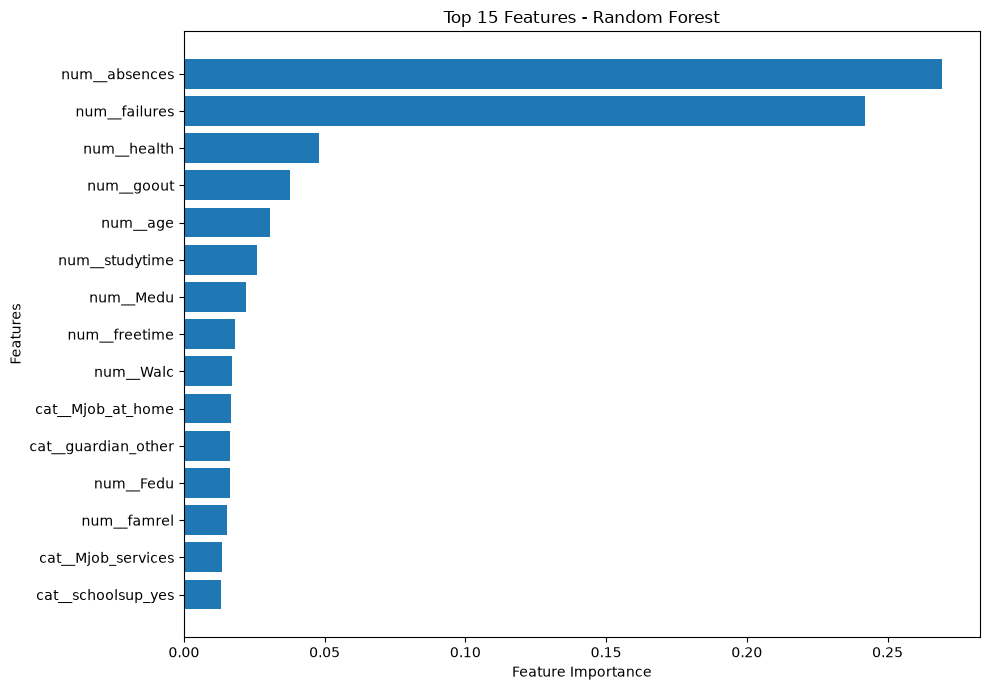

In [16]:

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features - Random Forest")

plt.tight_layout()
plt.show()


### 12. Saving the Final Model

In [17]:

os.makedirs("../artifacts", exist_ok=True)

# Save the selected Random Forest model
joblib.dump(
    rf_model,
    "../artifacts/student_performance_model.pkl"
)

# Save model evaluation metrics
model_metrics = {
    "model": "Random Forest Regressor",
    "test_mae": rf_mae,
    "test_rmse": rf_rmse,
    "test_r2": rf_r2,
    "cv_mae": 2.959,
    "cv_std": 0.198
}

joblib.dump(
    model_metrics,
    "../artifacts/model_metrics.pkl"
)

# Save feature importance
importance_df.to_csv(
    "../artifacts/feature_importance.csv",
    index=False
)

print("Model and evaluation artifacts saved successfully!")


Model and evaluation artifacts saved successfully!


### 13. Model Reloading and Verification

In [18]:

# Verify saved artifact files
artifact_files = [
    "../artifacts/student_performance_model.pkl",
    "../artifacts/model_metrics.pkl",
    "../artifacts/feature_importance.csv"
]

print("Artifact Verification")
print("---------------------")

for file_path in artifact_files:
    print(
        os.path.basename(file_path),
        ":",
        "Exists" if os.path.exists(file_path) else "Missing"
    )

# Reload saved model and metrics
loaded_model = joblib.load(
    "../artifacts/student_performance_model.pkl"
)

loaded_metrics = joblib.load(
    "../artifacts/model_metrics.pkl"
)

# Generate predictions using reloaded model
reloaded_predictions = loaded_model.predict(X_test)

# Compare predictions
predictions_match = np.allclose(
    rf_predictions,
    reloaded_predictions
)

print("\nModel Reload Verification")
print("-------------------------")
print("Predictions Match:", predictions_match)
print("Reloaded Model:", type(loaded_model).__name__)
print("Saved Test MAE:", round(loaded_metrics["test_mae"], 3))
print("Saved Test RMSE:", round(loaded_metrics["test_rmse"], 3))
print("Saved Test R2:", round(loaded_metrics["test_r2"], 3))


Artifact Verification
---------------------
student_performance_model.pkl : Exists
model_metrics.pkl : Exists
feature_importance.csv : Exists

Model Reload Verification
-------------------------
Predictions Match: True
Reloaded Model: RandomForestRegressor
Saved Test MAE: 3.166
Saved Test RMSE: 3.934
Saved Test R2: 0.245


## Day 04: Model Development and Evaluation — Summary

### Objective
Develop, train, evaluate, and select suitable machine-learning regression models for predicting students' final mathematics grades.

### Tasks Completed
1. Loaded the preprocessed training and testing datasets.
2. Established a baseline using Dummy Regressor.
3. Trained and evaluated Linear Regression, Decision Tree, Random Forest, and Gradient Boosting models.
4. Compared models using MAE, RMSE, and R².
5. Performed 5-fold cross-validation.
6. Evaluated potential overfitting.
7. Tuned Random Forest hyperparameters and compared generalization performance.
8. Created Actual vs. Predicted and Residual Analysis visualizations.
9. Extracted and visualized Random Forest feature importance.
10. Selected the original Random Forest model based on test and cross-validation performance.
11. Saved and verified the trained model and evaluation artifacts.

### Final Model Performance
- Selected Model: Random Forest Regressor
- Test MAE: 3.166
- Test RMSE: 3.934
- Test R²: 0.245
- 5-Fold CV MAE: 2.959

### Key Findings
Absences and previous class failures were the two most influential features in the selected model. The model showed some overfitting and difficulty predicting extreme grades.

### Artifacts Generated
- student_performance_model.pkl
- model_metrics.pkl
- feature_importance.csv

### Conclusion
Model development and evaluation were completed successfully. The selected Random Forest model was saved, reloaded, and verified to produce matching predictions. Further improvement in predictive performance and generalization remains possible.